# CAPSTONE PROJECT 3 - Classification Problem (by Mayank Raj Pachouri)

#### Problem Statement: Financial Fraud Detection (predict whether the transaction is Fraud or not)

### 1. Importing all the Essential libraries

In [1]:
# Libraries required to extract data from database, Convert the data into Dataframe and to Visualize the data

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
import warnings 
warnings.filterwarnings('ignore')

# Libraries required for the Preprocessing of Data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Libraries required for various Classification Models

### Models Selected for the Classification problem are:
# 1. Logistic Regression,
# 2. K-Nearest Neighbours (KNN - Classification),
# 3. Support Vector Machines (SVM- Classifier),
# 4. Decison Tree Classifier,
# 5. Random Forest Classifier,
# 6. XGBoost &
# 7. Neural Network Classifier

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Libraries required specifically for Neural Network Classifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Additional libraries required for the Execution of Model

from collections import Counter
from math import sqrt
from sklearn.impute import SimpleImputer  # To Import the missing piece
from scipy import stats  # To perform Hypothesis Testing


# Libraries required to evaluate the Performance of the Model

from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, classification_report
from sklearn.metrics import precision_recall_curve

### confusion_matrix      → Shows correct and incorrect predictions for each class (TP, TN, FP, FN)
### accuracy_score        → Measures the percentage of total predictions that are correct
### roc_curve             → Shows the trade-off between True Positive Rate and False Positive Rate at different thresholds
### classification_report → Provides precision, recall, F1-score, and support for each class
### precision_recall_curve→ Shows the trade-off between Precision and Recall at different thresholds

sns.set_theme(style="whitegrid", palette="muted")
#Setting the theme to White with Grid lines and  with subdued colors
plt.rcParams['figure.figsize'] = (10,5)
plt.rcParams['axes.titlesize']= 14

print("All the libraries have been imported successfully")

All the libraries have been imported successfully


### 2. Load & Explore Dataset

##### Loading Data from Database

In [2]:
# Creating connection to the SQLite Database file
conn = sqlite3.connect(r'C:\Users\user\Downloads\classification.db')
#Please replace the path 'C:\Users\user\Downloads\classification.db' if the Database file is located in any other directoy.

# Creating a Cursor Object
cursor = conn.cursor()

# SQL Query to retrieve the Table names
cursor.execute("SELECT name FROM sqlite_master WHERE type = 'table';")

# Fetching all the Table names
tables = cursor.fetchall()

# Printing the table names
for table in tables:
    print (table[0])

fraud_detection
Heart_disease
Metro_Train_Maintenance
forest_cov_type
fake_news_classification
drug_reviews_sentiment_analysis
Telecom_microservices_loan
malware_detection
fault_detection_manufacturing


In [3]:
# Creating a Pandas Daraframe from the Table of Database
df = pd.read_sql_query("SELECT * FROM fraud_detection", conn)

In [4]:
# Closing the Connection with SQLite Database & Printing Dataframe
conn.close()
df.head(20)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0


In [5]:
# Understanding Features from the Database

# Step: Time step of the Transaction in Paysim, 1 step represents 1 hour
# Type: Type of Transaction 
# Amount: Amount of money involved in Transaction
# NameOrig: Name/ID of the Account from where the Transaction made its Origin (Sender Name)
# Oldbalanceorg: Balance of the destination account after the transaction (Sender Account Original Balance)
# Newbalanceorg: Balance of the destination account after the transaction (Sender Account New Balance) 
# namedest: Name/ID of the Account from where the Transaction made its End (Receiver Name) 
# oldbalancedest: Balance of the destination account after the transaction (Receiver Account Original Balance)
# Newbalancedest: Balance of the destination account after the transaction (Receiver Account New Balance) 
# isfraud: Target variable indicating whether the transaction is fraudulent
# isflaggedfraud: Whether the system's predefined rule flagged the transaction as potentially fraudulent 


#Predict label (isfraud)
# The Transaction is Fraudulent (binary: “1”, means “Yes”, “0” means “No”)

In [6]:
# Exploring Values from data to understand the Data Types, Value Counts & Missing values

In [7]:
# Checking the Null values & Data types of the Columns (Variables) present in Dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [8]:
print(df.isnull().sum())

step                   0
type              203603
amount                 0
nameOrig          203603
oldbalanceOrg          0
newbalanceOrig    267230
nameDest               0
oldbalanceDest    203603
newbalanceDest         0
isFraud                0
isFlaggedFraud         0
dtype: int64


In [9]:
# We see that the following variables have the Null/NaN (Missing) values in the dataset.

#1. Type - Type of Transaction 
#2. nameorig - Name/ID of the Account from where the Transaction made its Origin (Sender Name)
#3. newbalanceOrig - Balance of the destination account after the transaction (Sender Account New Balance) 
#4. oldbalanceDest - Balance of the destination account after the transaction (Receiver Account Original Balance)

In [10]:
df['step'].value_counts(dropna=False)

step
19     51352
18     49579
187    49083
235    47491
307    46968
       ...  
721        4
725        4
729        4
112        2
662        2
Name: count, Length: 743, dtype: int64

In [11]:
df['type'].value_counts(dropna=False)

type
CASH_OUT    2165868
PAYMENT     2082597
CASH_IN     1354742
TRANSFER     515688
NaN          203603
DEBIT         40122
Name: count, dtype: int64

In [12]:
df['isFraud'].value_counts(dropna=False)

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [13]:
df['isFlaggedFraud'].value_counts(dropna=False)

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

##### Based on above information we have the following observations and We need to perform following Data type conversions.

In [14]:
# Step is currently assigned with Data type 'int64' and the values ranges from (2,51352), It can be converted into 'int32' or 'uint16' for 
# memory optimization.
# Type is a string which contains 6 distinct values with ~3.19% values to be NaN, which requires Data type conversion via One Hot Encoding to 'uint8' 
# and Imputation of 'Unknown' value for 'NaN' (Helpful for Fraud Detection, Else we could have also used Mode Imputation)
# nameOrig, nameDest has a pattern where the 'nameOrig' starts with 'C' and 'nameDest' contains 'C' & 'M' values representing Merchant & Customer 
# respectively. Hence Extracting Prefix Flag & Dropping the Original values.
# isFraud - Converting the data type of label to 'int8' for Memory Optimization
# oldbalanceOrg, newbalanceOrig, oldbalanceDest & newbalanceDest - Converting the Data types to 'float32' for Memory optimization.

# From the exploration of Data we have observed that the Variables 'isFraud' & 'isFlaggedFraud' are Binary variables or we can also call them
# as Boolean variables where 0 represents 'No' od 'False' and 1 represents 'Yes' or 'True'.





# The Above Data type conversions are being performed to reduce the memory memory usage in half (~260 MB), making model training much faster. 

In [15]:
### Step basically means Time step, so converting Steps into Hour of day & Day of week
df['step'] = df['step'].astype('uint16')

# 1. Extract the Hour of the Day (0 to 23)
df['hour_of_day'] = df['step'] % 24

# 2. Extract the Day of the Week (assuming step starts on a Monday/Day 0)
df['day_of_week'] = (df['step'] // 24) % 7

# Now your model can map explicitly if fraud spikes at 3 AM on Saturdays!
df = df.drop(columns=['step'])

In [16]:
# Creating the binary flag directly for nameOrig (NaNs naturally become False, then we fill any remaining gaps)
df['is_known_customer_orig'] = df['nameOrig'].str.startswith('C', na=False).astype('int8')

# Drop the original string column
df = df.drop(columns=['nameOrig'])

In [17]:
df[['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']] = df[['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']].astype('float32')

#### Missing Value Imputation

In [18]:
# Performing Missing value Imputation

# For Categorical variable 'type' using mode value to impute missing values
df['type'] = df['type'].fillna('Unknown')

# For Numerical variable 'newbalanceOrig', Imputing the missing values with the difference observed by substracting the Transaction Amount from Old Balance.
df['newbalanceOrig'] = df['newbalanceOrig'].fillna(
    df['oldbalanceOrg'] - df['amount']
)

# For Numerical variable 'oldbalanceDest', using median as the Old Balance of Destination account is usually not a fixed number
df['oldbalanceDest'] = df['oldbalanceDest'].fillna(
    df['oldbalanceDest'].median()
)

In [19]:
# Checking the data again to see if there are any missing values

print(df.isnull().sum())

type                      0
amount                    0
oldbalanceOrg             0
newbalanceOrig            0
nameDest                  0
oldbalanceDest            0
newbalanceDest            0
isFraud                   0
isFlaggedFraud            0
hour_of_day               0
day_of_week               0
is_known_customer_orig    0
dtype: int64


#### Performing One Hot Encoding for Variable 'Type'

In [20]:
df = pd.get_dummies(df, columns=['type'], drop_first=True)

#### Feature Engineering

In [21]:
# Since nameDest (Name of Destination) has 2 types of values which either start with C (Customer) or M (Merchant)
# Hence extracting the initial value and converting it into Integer variable

df['is_merchant_dest'] = df['nameDest'].str.startswith('M').astype(int)

In [22]:
df['is_merchant_dest'].value_counts(dropna=False)

is_merchant_dest
0    4211125
1    2151495
Name: count, dtype: int64

In [23]:
# Since nameDest has been converted into another variable, we will be removing the redundant column

df = df.drop(columns=['nameDest'])

In [24]:
## Creating additional features for the better understanding of data and to identify Patterns

### Additional Features are as follows:
#1. amount_diff_orig - Amount difference observed at Origin by substracting New balance Origin from Old Balance Origin
#2. amount_diff_dest - Amount difference observed at Destination by substracting Old balance Destination from New Balance Destination
#3. orig_discrepancy - Difference between the Transaction amount and the Amount difference observed at Origin
#4. dest_discrepancy - Difference between the Transaction amount and the Amount difference observed at Destination
#5. orig_amount_ratio - Transaction Amount with respect to the Old Balance at Origin
#6. dest_amount_ratio - Transaction Amount with respect to the Old Balance at Destination


df['amount_diff_orig'] = (df['oldbalanceOrg'] - df['newbalanceOrig'])

df['amount_diff_dest'] = (df['newbalanceDest'] - df['oldbalanceDest'])

df['orig_discrepancy'] = (df['amount'] - df['amount_diff_orig'])

df['dest_discrepancy'] = (df['amount'] - df['amount_diff_dest'])

df['orig_amount_ratio'] = (df['amount_diff_orig'] / df['amount'].replace(0, np.nan))

df['dest_amount_ratio'] = (df['amount_diff_dest'] / df['amount'].replace(0, np.nan))

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 22 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   amount                  float32
 1   oldbalanceOrg           float32
 2   newbalanceOrig          float32
 3   oldbalanceDest          float32
 4   newbalanceDest          float32
 5   isFraud                 int64  
 6   isFlaggedFraud          int64  
 7   hour_of_day             uint16 
 8   day_of_week             uint16 
 9   is_known_customer_orig  int8   
 10  type_CASH_OUT           bool   
 11  type_DEBIT              bool   
 12  type_PAYMENT            bool   
 13  type_TRANSFER           bool   
 14  type_Unknown            bool   
 15  is_merchant_dest        int64  
 16  amount_diff_orig        float32
 17  amount_diff_dest        float32
 18  orig_discrepancy        float32
 19  dest_discrepancy        float32
 20  orig_amount_ratio       float32
 21  dest_amount_ratio       float32
dtypes: bo

In [26]:
df.describe()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour_of_day,day_of_week,is_known_customer_orig,is_merchant_dest,amount_diff_orig,amount_diff_dest,orig_discrepancy,dest_discrepancy,orig_amount_ratio,dest_amount_ratio
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6362620.000,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362604e+06,6.362604e+06
mean,1.798619e+05,8.338831e+05,8.467134e+05,1.070159e+06,1.224996e+06,1.290820e-03,2.514687e-06,1.532145e+01,2.481576e+00,0.968,3.381461e-01,-1.283031e+04,1.548377e+05,1.926922e+05,2.502418e+04,9.042799e-02,1.599971e+00
std,6.038582e+05,2.888243e+06,2.925347e+06,3.357521e+06,3.674129e+06,3.590480e-02,1.585775e-03,4.321799e+00,2.165331e+00,0.176,4.730786e-01,1.905360e+05,1.019487e+06,5.961844e+05,7.317729e+05,6.914148e-01,1.394503e+03
min,0.000000e+00,0.000000e+00,-4.795285e+07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000,0.000000e+00,-1.915268e+06,-1.306083e+07,-2.529785e+00,-1.854519e+08,-1.162791e+00,-4.741722e+05
25%,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.200000e+01,1.000000e+00,1.000,0.000000e+00,0.000000e+00,0.000000e+00,2.523350e+02,0.000000e+00,0.000000e+00,0.000000e+00
50%,7.487194e+04,1.420800e+04,0.000000e+00,1.327682e+05,2.146614e+05,0.000000e+00,0.000000e+00,1.600000e+01,2.000000e+00,1.000,0.000000e+00,0.000000e+00,0.000000e+00,5.617243e+04,3.575900e+03,0.000000e+00,0.000000e+00
75%,2.087215e+05,1.073152e+05,1.401753e+05,8.930225e+05,1.111909e+06,0.000000e+00,0.000000e+00,1.900000e+01,5.000000e+00,1.000,1.000000e+00,1.137951e+04,1.553757e+05,2.390435e+05,3.280303e+04,9.507148e-01,1.000000e+00
max,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00,2.300000e+01,6.000000e+00,1.000,1.000000e+00,4.795285e+07,1.855964e+08,9.244552e+07,1.319123e+07,1.044497e+00,3.242458e+06


## Visualizing the Data

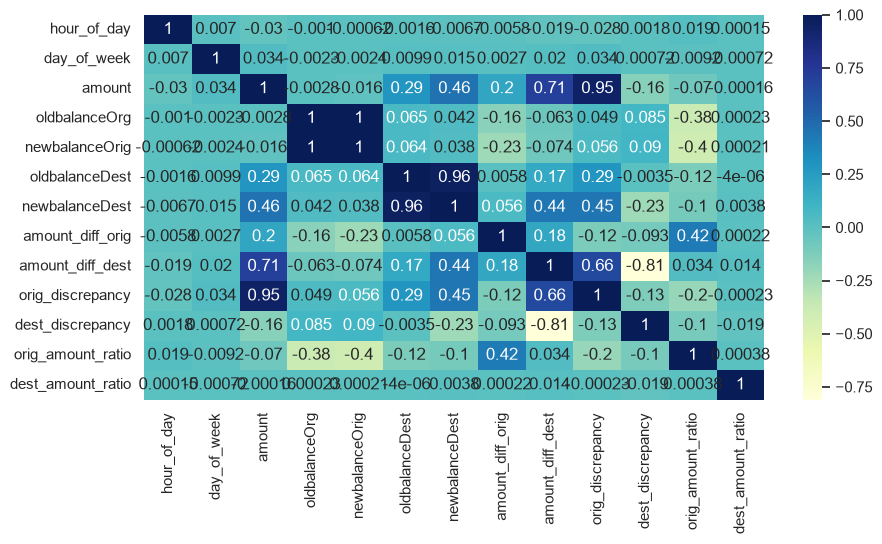

In [27]:
#Visualizing the Corelation between Numerical variables

#Correlation of output with numerical variables
numerical_columns = ['hour_of_day', 'day_of_week', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'amount_diff_orig', 'amount_diff_dest', 'orig_discrepancy', 'dest_discrepancy', 'orig_amount_ratio', 'dest_amount_ratio']

# plotting correlation heatmap
dataplot = sns.heatmap(df[numerical_columns].corr(), cmap="YlGnBu", annot=True)

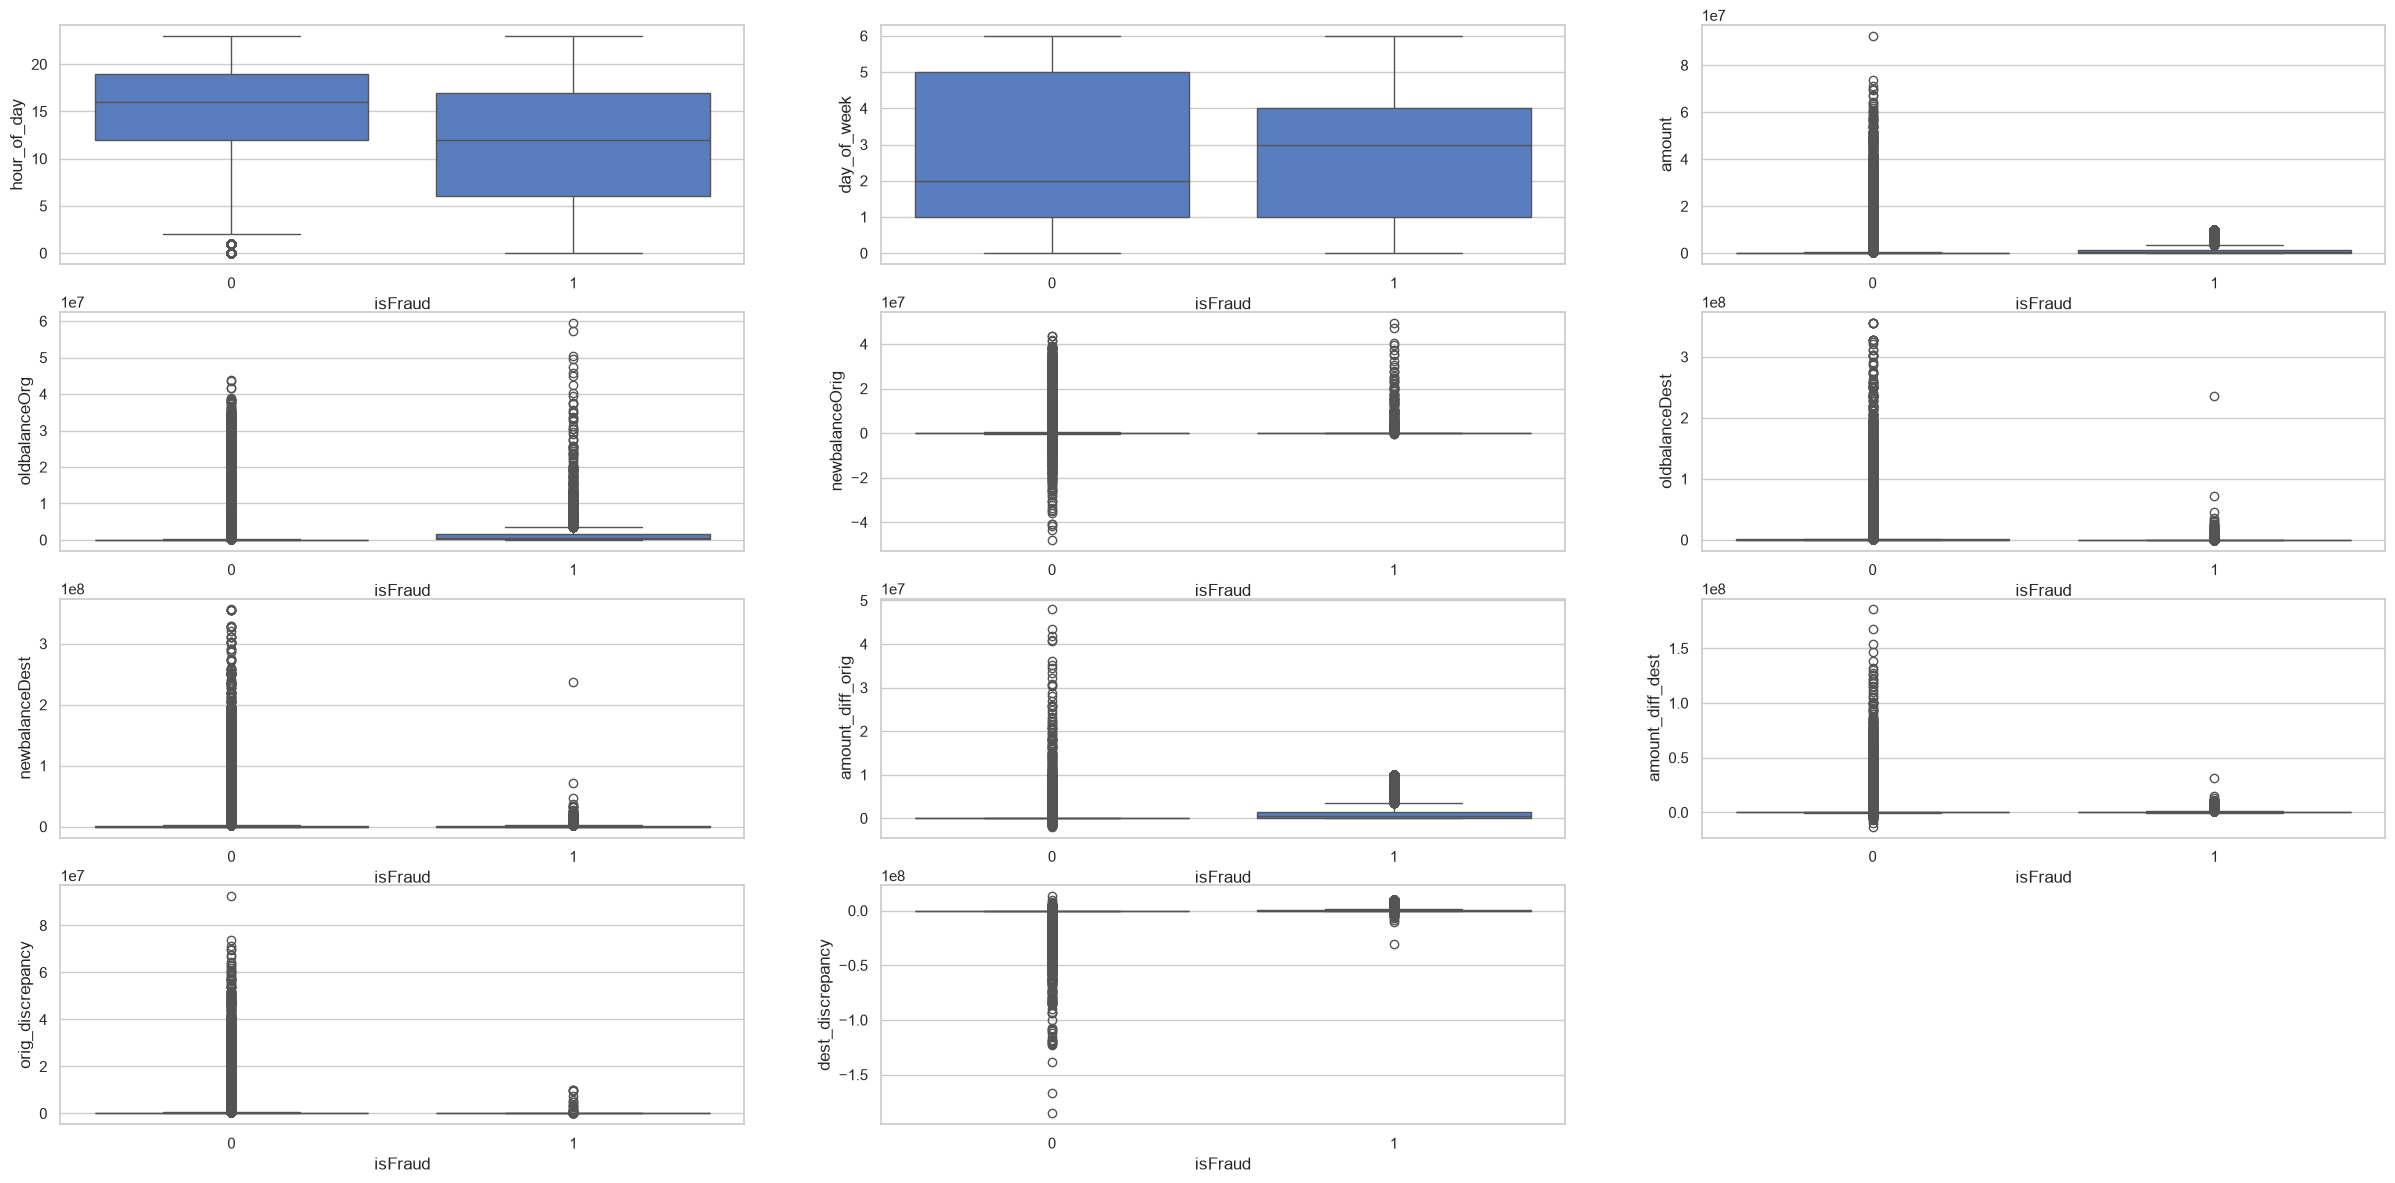

In [28]:
#Visualizing numerical variables

plt.figure(figsize=(30, 18))
plt.subplot(5,3,1)
sns.boxplot(x = 'isFraud', y = 'hour_of_day', data = df)
plt.subplot(5,3,2)
sns.boxplot(x = 'isFraud', y = 'day_of_week', data = df)
plt.subplot(5,3,3)
sns.boxplot(x = 'isFraud', y = 'amount', data = df)
plt.subplot(5,3,4)
sns.boxplot(x = 'isFraud', y = 'oldbalanceOrg', data = df)
plt.subplot(5,3,5)
sns.boxplot(x = 'isFraud', y = 'newbalanceOrig', data = df)
plt.subplot(5,3,6)
sns.boxplot(x = 'isFraud', y = 'oldbalanceDest', data = df)
plt.subplot(5,3,7)
sns.boxplot(x = 'isFraud', y = 'newbalanceDest', data = df)
plt.subplot(5,3,8)
sns.boxplot(x = 'isFraud', y = 'amount_diff_orig', data = df)
plt.subplot(5,3,9)
sns.boxplot(x = 'isFraud', y = 'amount_diff_dest', data = df)
plt.subplot(5,3,10)
sns.boxplot(x = 'isFraud', y = 'orig_discrepancy', data = df)
plt.subplot(5,3,11)
sns.boxplot(x = 'isFraud', y = 'dest_discrepancy', data = df)



plt.savefig("fraud_features_boxplots.png", dpi=300, bbox_inches="tight")

##### Feature selection based on correlation analysis: remove highly correlated and redundant variables to minimize multicollinearity and improve model efficiency.
##### Dropping: 'newbalanceOrig', 'newbalanceDest', 'dest_amount_ratio', 'day_of_week'


In [29]:
columns_to_drop = ['newbalanceOrig', 'newbalanceDest', 'dest_amount_ratio', 'day_of_week']

df = df.drop(columns=columns_to_drop)

In [30]:
numerical_columns = ['hour_of_day', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_diff_orig', 'amount_diff_dest', 'orig_discrepancy', 'dest_discrepancy', 'orig_amount_ratio']


#### Performing Hypothesis Testing

In [31]:
data_isFraud = df[df['isFraud'] == 1]
data_isFraud[numerical_columns].describe()

,hour_of_day,amount,oldbalanceOrg,oldbalanceDest,amount_diff_orig,amount_diff_dest,orig_discrepancy,dest_discrepancy,orig_amount_ratio
count,8213.000000,8.213000e+03,8.213000e+03,8.213000e+03,8.213000e+03,8.213000e+03,8.213000e+03,8.213000e+03,8197.000000
mean,11.546451,1.467967e+06,1.649668e+06,5.357396e+05,1.457371e+06,7.439680e+05,1.059653e+04,7.239993e+05,0.994873
std,6.874612,2.404253e+06,3.547720e+06,3.315624e+06,2.396050e+06,1.899017e+06,2.650728e+05,1.911781e+06,0.071004
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.152261e+05,-2.000000e+00,-3.030357e+07,0.000000
25%,6.000000,1.270913e+05,1.258224e+05,0.000000e+00,1.246970e+05,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
50%,12.000000,4.414234e+05,4.389834e+05,0.000000e+00,4.363175e+05,0.000000e+00,0.000000e+00,7.618490e+03,1.000000
75%,17.000000,1.517772e+06,1.517772e+06,1.327682e+05,1.503035e+06,4.490329e+05,0.000000e+00,4.482669e+05,1.000000
max,23.000000,1.000000e+07,5.958504e+07,2.362305e+08,1.000000e+07,3.154469e+07,1.000000e+07,1.013277e+07,1.000000


In [32]:
data_not_Fraud = df[df['isFraud'] == 0]
data_not_Fraud[numerical_columns].describe()

,hour_of_day,amount,oldbalanceOrg,oldbalanceDest,amount_diff_orig,amount_diff_dest,orig_discrepancy,dest_discrepancy,orig_amount_ratio
count,6.354407e+06,6.354407e+06,6354407.00,6.354407e+06,6.354407e+06,6.354407e+06,6.354407e+06,6.354407e+06,6.354407e+06
mean,1.532633e+01,1.781970e+05,832828.75,1.070849e+06,-1.473052e+04,1.540763e+05,1.929276e+05,2.412076e+04,8.926128e-02
std,4.315387e+00,5.962370e+05,2887144.00,3.357520e+06,1.616608e+05,1.017638e+06,5.964575e+05,7.285794e+05,6.910919e-01
min,0.000000e+00,1.000000e-02,0.00,0.000000e+00,-1.915268e+06,-1.306083e+07,-2.529785e+00,-1.854519e+08,-1.162791e+00
25%,1.200000e+01,1.336840e+04,0.00,0.000000e+00,0.000000e+00,0.000000e+00,3.332251e+02,0.000000e+00,0.000000e+00
50%,1.600000e+01,7.468472e+04,14069.00,1.327682e+05,0.000000e+00,0.000000e+00,5.654696e+04,3.575610e+03,0.000000e+00
75%,1.900000e+01,2.083648e+05,106969.50,8.940853e+05,1.133100e+04,1.552457e+05,2.393659e+05,3.268475e+04,9.350699e-01
max,2.300000e+01,9.244552e+07,43818856.00,3.560159e+08,4.795285e+07,1.855964e+08,9.244552e+07,1.319123e+07,1.044497e+00


In [33]:
### Performing Welch-T Test 
## checking relation beween numerical column and categorical columns
## checking relation between hour_of_day, amount, oldbalanceOrg, oldbalanceDest, amount_diff_orig, amount_diff_dest, orig_discrepancy, dest_discrepancy & orig_amount_ratio and isFraud

## If for any feature - p >0.05 then this feature might not be useful just on its own
## But it can still be useful when combined with other features
  
# defining the table
for column in numerical_columns:
        samples_set1 = data_isFraud[column]
        samples_set2 = data_not_Fraud[column]
        stat, p = stats.ttest_ind(samples_set1, samples_set2)
    
        print("ttest for feature: ", column)
        print("p-value : ", p)
        print("")
        print("")

ttest for feature:  hour_of_day
p-value :  0.0


ttest for feature:  amount
p-value :  0.0


ttest for feature:  oldbalanceOrg
p-value :  0.0


ttest for feature:  oldbalanceDest
p-value :  0.0


ttest for feature:  amount_diff_orig
p-value :  0.0


ttest for feature:  amount_diff_dest
p-value :  0.0


ttest for feature:  orig_discrepancy
p-value :  0.0


ttest for feature:  dest_discrepancy
p-value :  0.0


ttest for feature:  orig_amount_ratio
p-value :  nan




In [34]:
df[df['isFraud'] == 1]

,amount,oldbalanceOrg,oldbalanceDest,isFraud,isFlaggedFraud,hour_of_day,is_known_customer_orig,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,type_Unknown,is_merchant_dest,amount_diff_orig,amount_diff_dest,orig_discrepancy,dest_discrepancy,orig_amount_ratio
2,181.000,181.000,0.000000e+00,1,0,1,1,False,False,False,True,False,0,181.000,0.000,0.0,181.0,1.0
3,181.000,181.000,2.118200e+04,1,0,1,1,True,False,False,False,False,0,181.000,-21182.000,0.0,21363.0,1.0
251,2806.000,2806.000,0.000000e+00,1,0,1,1,False,False,False,True,False,0,2806.000,0.000,0.0,2806.0,1.0
252,2806.000,2806.000,2.620200e+04,1,0,1,1,True,False,False,False,False,0,2806.000,-26202.000,0.0,29008.0,1.0
680,20128.000,20128.000,0.000000e+00,1,0,1,1,False,False,False,True,False,0,20128.000,0.000,0.0,20128.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6362615,339682.125,339682.125,0.000000e+00,1,0,23,1,True,False,False,False,False,0,339682.125,339682.125,0.0,0.0,1.0
6362616,6311409.500,6311409.500,0.000000e+00,1,0,23,1,False,False,False,True,False,0,6311409.500,0.000,0.0,6311409.5,1.0
6362617,6311409.500,6311409.500,6.848884e+04,1,0,23,1,True,False,False,False,False,0,6311409.500,6311409.000,0.0,0.5,1.0
6362618,850002.500,850002.500,0.000000e+00,1,0,23,1,False,False,False,True,False,0,850002.500,0.000,0.0,850002.5,1.0


In [35]:
df[df['isFraud'] == 0]

,amount,oldbalanceOrg,oldbalanceDest,isFraud,isFlaggedFraud,hour_of_day,is_known_customer_orig,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,type_Unknown,is_merchant_dest,amount_diff_orig,amount_diff_dest,orig_discrepancy,dest_discrepancy,orig_amount_ratio
0,9839.639648,170136.0,0.000000,0,0,1,1,False,False,True,False,False,1,9839.640625,0.000000,-0.000977,9839.639648,1.000000
1,1864.280029,21249.0,0.000000,0,0,1,1,False,False,True,False,False,1,1864.279297,0.000000,0.000732,1864.280029,1.000000
4,11668.139648,41554.0,0.000000,0,0,1,1,False,False,True,False,False,1,11668.140625,0.000000,-0.000977,11668.139648,1.000000
5,7817.709961,53860.0,0.000000,0,0,1,1,False,False,True,False,False,1,7817.710938,0.000000,-0.000977,7817.709961,1.000000
6,7107.770020,183195.0,0.000000,0,0,1,1,False,False,True,False,False,1,7107.765625,0.000000,0.004395,7107.770020,0.999999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6362319,8634.290039,518802.0,0.000000,0,0,22,1,False,False,True,False,False,1,8634.281250,0.000000,0.008789,8634.290039,0.999999
6362320,159188.218750,3859.0,0.000000,0,0,22,1,True,False,False,False,False,0,3859.000000,159188.218750,155329.218750,0.000000,0.024242
6362321,186273.843750,168046.0,24893.669922,0,0,22,1,True,False,False,False,False,0,168046.000000,186273.843750,18227.843750,0.000000,0.902145
6362322,82096.453125,13492.0,0.000000,0,0,22,1,False,False,False,True,False,0,13492.000000,82096.453125,68604.453125,0.000000,0.164343


In [36]:
df['isFraud'].value_counts(normalize=True)

isFraud
0    0.998709
1    0.001291
Name: proportion, dtype: float64

### Training & Testing Split

In [48]:
def train_test_split_and_scale(df):

    y = df["isFraud"]

    x = df.drop("isFraud", axis=1)

    print("Features before train-test split:")
    print(x.dtypes)

    print("\nObject columns:")
    print(x.select_dtypes(include=["object"]).columns)

    features = list(x.columns)
    
## Stratified Split (Crucial for your 0.13% fraud class imbalance)
    x_train, x_test, y_train, y_test = train_test_split(
        x,
        y,
        test_size=0.30,
        random_state=0,
        stratify=y
    )

## NEW STEP: Impute any remaining NaNs using the column median
# We use median because it is robust against massive financial outliers
    imputer = SimpleImputer(strategy='median')
    x_train = imputer.fit_transform(x_train)
    x_test = imputer.transform(x_test)

    scaler = MinMaxScaler()

    x_train = scaler.fit_transform(x_train)
    x_test = scaler.transform(x_test)

    return x_train, x_test, y_train, y_test, features

In [49]:
x_train, x_test, y_train, y_test, features = train_test_split_and_scale(df)

Features before train-test split:
amount                    float32
oldbalanceOrg             float32
oldbalanceDest            float32
isFlaggedFraud              int64
hour_of_day                uint16
is_known_customer_orig       int8
type_CASH_OUT                bool
type_DEBIT                   bool
type_PAYMENT                 bool
type_TRANSFER                bool
type_Unknown                 bool
is_merchant_dest            int64
amount_diff_orig          float32
amount_diff_dest          float32
orig_discrepancy          float32
dest_discrepancy          float32
orig_amount_ratio         float32
dtype: object

Object columns:
Index([], dtype='str')


## Model 1: Logistic Regression

In [52]:
def fit_and_evaluate_model(x_train, x_test, y_train, y_test,class_weight=None):
    lr = LogisticRegression(class_weight=class_weight)
    model = lr.fit(x_train, y_train) # model training
    lr_predict = lr.predict(x_test) # create predicted o/p 0/1
    lr_conf_matrix = confusion_matrix(y_test, lr_predict)
    lr_acc_score = accuracy_score(y_test, lr_predict)
    print("confussion matrix")
    print(lr_conf_matrix)
    print("\n")
    print("Accuracy of Logistic Regression:",lr_acc_score*100,'\n')
    print(classification_report(y_test,lr_predict))
    return model

In [51]:
model = fit_and_evaluate_model(x_train, x_test, y_train, y_test)
print("odds ratio", np.exp(model.coef_))

confussion matrix
[[1906091     231]
 [   2313     151]]


Accuracy of Logistic Regression: 99.86672157067372 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906322
           1       0.40      0.06      0.11      2464

    accuracy                           1.00   1908786
   macro avg       0.70      0.53      0.55   1908786
weighted avg       1.00      1.00      1.00   1908786

odds ratio [[1.67233001e+00 1.81688016e+00 8.67002718e-01 1.07565733e+00
  3.91788404e-03 1.65781603e-02 1.88165054e+01 6.89665155e-01
  3.32595197e-02 1.23323400e+02 1.35051632e-01 1.66680644e-02
  2.64005680e+00 7.13963010e-01 8.72948440e-01 3.99982726e-03
  9.02138301e+04]]


## Model 2: XGBoost Classifier

In [53]:
# Calculate the balance weight factor
scale_weight = 1906322 / 2464

# Initialize the model with the 'xgb' alias
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_weight,
    random_state=0,
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    n_jobs=-1
)

# Train the model
xgb_model.fit(x_train, y_train)

# Predict and print evaluations
y_pred_xgb = xgb_model.predict(x_test)
print("--- XGBoost Evaluation ---")
print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

--- XGBoost Evaluation ---
[[1892574   13748]
 [      6    2458]]
              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1906322
           1       0.15      1.00      0.26      2464

    accuracy                           0.99   1908786
   macro avg       0.58      1.00      0.63   1908786
weighted avg       1.00      0.99      1.00   1908786



## Model 3: KNN Classifier

In [55]:
# --- Memory Optimization: Sample 1% of the data using stratification ---
# This ensures the 0.13% fraud ratio remains identical in our sample
from sklearn.model_selection import train_test_split
x_train_sample, _, y_train_sample, _ = train_test_split(
    x_train, y_train, train_size=0.01, random_state=0, stratify=y_train
)

# Initialize KNN (using weights='distance' helps combat class imbalance)
knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)

# Train on the optimized sample size
knn_model.fit(x_train_sample, y_train_sample)

# Predict on the full test set
y_pred_knn = knn_model.predict(x_test)

print("--- K-Nearest Neighbors Evaluation ---")
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

--- K-Nearest Neighbors Evaluation ---
[[1905971     351]
 [   1693     771]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906322
           1       0.69      0.31      0.43      2464

    accuracy                           1.00   1908786
   macro avg       0.84      0.66      0.71   1908786
weighted avg       1.00      1.00      1.00   1908786



## Model 4: Support Vector Machines (SVM Classifier)

In [56]:
# Initialize Linear SVM
# 'class_weight=balanced' handles the extreme 0.13% fraud imbalance automatically
svm_model = LinearSVC(
    class_weight='balanced', 
    random_state=0, 
    max_iter=1000, 
    dual=False # Highly recommended when number of samples > number of features
)

# Train the model
svm_model.fit(x_train, y_train)

# Predict and Evaluate
y_pred_svm = svm_model.predict(x_test)

print("--- Support Vector Machine Evaluation ---")
print(confusion_matrix(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

--- Support Vector Machine Evaluation ---
[[1769044  137278]
 [      8    2456]]
              precision    recall  f1-score   support

           0       1.00      0.93      0.96   1906322
           1       0.02      1.00      0.03      2464

    accuracy                           0.93   1908786
   macro avg       0.51      0.96      0.50   1908786
weighted avg       1.00      0.93      0.96   1908786



## Model 5: Decison Tree Classifier 

In [57]:
# Initialize Decision Tree
tree_model = DecisionTreeClassifier(
    class_weight='balanced', 
    max_depth=10,             # Prevents explosive tree growth on 6M rows
    random_state=0
)

# Train the model
tree_model.fit(x_train, y_train)

# Predict and Evaluate
y_pred_tree = tree_model.predict(x_test)

print("--- Decision Tree Evaluation ---")
print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree))

--- Decision Tree Evaluation ---
[[1841905   64417]
 [     16    2448]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.98   1906322
           1       0.04      0.99      0.07      2464

    accuracy                           0.97   1908786
   macro avg       0.52      0.98      0.53   1908786
weighted avg       1.00      0.97      0.98   1908786



## Model 6: Random Forest Classifier

In [58]:
# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=50,          # Reduced from 100 to save processing time
    class_weight='balanced', 
    max_depth=12,             # Caps individual tree size for memory optimization
    n_jobs=-1,                # Uses all available CPU threads
    random_state=0
)

# Train the model
rf_model.fit(x_train, y_train)

# Predict and Evaluate
y_pred_rf = rf_model.predict(x_test)

print("--- Random Forest Evaluation ---")
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))


--- Random Forest Evaluation ---
[[1877716   28606]
 [     18    2446]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99   1906322
           1       0.08      0.99      0.15      2464

    accuracy                           0.99   1908786
   macro avg       0.54      0.99      0.57   1908786
weighted avg       1.00      0.99      0.99   1908786



## Model 7: Neural Network (MLP Classifier)

In [59]:
# 1. FIX THE IMBALANCE: Calculate class weights for Keras
# This tells Keras that a fraud instance is ~774x more important than a legal one
neg, pos = np.bincount(y_train)
total = neg + pos
weight_for_0 = (1 / neg) * (total / 2.0)
weight_for_1 = (1 / pos) * (total / 2.0)
class_weights = {0: weight_for_0, 1: weight_for_1}

# 2. DESIGN THE ARCHITECTURE (Hidden layers matching your MLP: 64, 32)
keras_model = keras.Sequential([
    # Input layer needs to know how many features you have
    layers.Input(shape=(x_train.shape[1],)),
    
    # First Hidden Layer (64 neurons)
    layers.Dense(64, activation='relu'),
    # Adding Dropout is highly recommended for fraud models to prevent overfitting
    layers.Dropout(0.2), 
    
    # Second Hidden Layer (32 neurons)
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    
    # Output Layer (1 neuron with Sigmoid for binary classification probability)
    layers.Dense(1, activation='sigmoid')
])

# 3. COMPILE THE MODEL
keras_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy', # Standard for binary classification
    metrics=[keras.metrics.Precision(name='precision'), 
             keras.metrics.Recall(name='recall')]
)

# 4. TRAIN THE MODEL
print("--- Training Keras Neural Network ---")
history = keras_model.fit(
    x_train, y_train,
    validation_split=0.1,      # Automatically holds out 10% to check for overfitting
    batch_size=2048,           # Large batch size to handle your 6M rows efficiently
    epochs=15,                 # Low epoch count to keep execution times reasonable
    class_weight=class_weights, # Passes the imbalance adjustment to the gradients
    verbose=1
)

# 5. PREDICT AND EVALUATE
# Keras outputs continuous probabilities between 0 and 1
y_pred_probs = keras_model.predict(x_test, batch_size=2048)

# Convert probabilities to hard binary 0 or 1 classes (Default threshold = 0.50)
y_pred_keras = (y_pred_probs > 0.50).astype(int).flatten()

print("\n--- Keras Neural Network Evaluation ---")
print(confusion_matrix(y_test, y_pred_keras))
print(classification_report(y_test, y_pred_keras))

--- Training Keras Neural Network ---
Epoch 1/15
1958/1958 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.1755 - precision: 0.0127 - recall: 0.9752 - val_loss: 0.1491 - val_precision: 0.0191 - val_recall: 0.9932
Epoch 2/15
1958/1958 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1203 - precision: 0.0191 - recall: 0.9884 - val_loss: 0.1088 - val_precision: 0.0204 - val_recall: 0.9966
Epoch 3/15
1958/1958 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.1129 - precision: 0.0196 - recall: 0.9884 - val_loss: 0.1274 - val_precision: 0.0199 - val_recall: 0.9966
Epoch 4/15
1958/1958 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1107 - precision: 0.0198 - recall: 0.9891 - val_loss: 0.1057 - val_precision: 0.0204 - val_recall: 0.9966
Epoch 5/15
1958/1958 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1094 - precision: 0.0200 - recall: 0.9888 - val_loss: 0.1237 - val_precision: 0.0202 - val_recall: 0.9966
Epoch 6/15
1958/1958 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.1089 - precision: 0.0199 - recall: 0.9870 - val_

### Comparative performance evaluation across multiple model architectures to maximize minority-class F1-score and recall


In [62]:
# 1. Define a list of your trained models and their names
# (Make sure these variable names match what you used during training)
import pandas as pd
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Define the trained models
model_list = {
    "Logistic Regression": model,
    "K-Nearest Neighbors": knn_model,
    "Support Vector Machine": svm_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Neural Network (MLP)": keras_model
}

# 2. Collect fraud-class performance metrics
summary_data = []

for name, clf in model_list.items():

    # Generate predictions
    if name == "Neural Network (MLP)":
        # Convert Keras probabilities into class labels
        y_pred_probs = clf.predict(x_test, batch_size=2048, verbose=0)
        y_pred = (y_pred_probs.ravel() >= 0.50).astype(int)
    else:
        y_pred = clf.predict(x_test)

    # Calculate metrics for Fraud = 1
    precision = precision_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    summary_data.append({
        "Model Name": name,
        "Precision (Fraud)": round(precision, 4),
        "Recall (Fraud)": round(recall, 4),
        "F1-Score (Fraud)": round(f1, 4)
    })

# 3. Create and sort the comparison table
df_summary = pd.DataFrame(summary_data).sort_values(
    by="F1-Score (Fraud)",
    ascending=False
)

print("=== Unified Performance Comparison Table ===")
print(df_summary.to_string(index=False))

=== Unified Performance Comparison Table ===
            Model Name  Precision (Fraud)  Recall (Fraud)  F1-Score (Fraud)
   K-Nearest Neighbors             0.6872          0.3129            0.4300
               XGBoost             0.1517          0.9976            0.2633
         Random Forest             0.0788          0.9927            0.1460
   Logistic Regression             0.3953          0.0613            0.1061
         Decision Tree             0.0366          0.9935            0.0706
  Neural Network (MLP)             0.0195          0.9968            0.0382
Support Vector Machine             0.0176          0.9968            0.0345


##### Based o the above results XGBoost is the best overall model from this selection, despite K-Nearest Neighbors (KNN) sitting at the top of the table based purely on the default F1-score sorting.

##### • Near-Perfect Detection (99.76% Recall): XGBoost caught 99.76% of all fraudulent transactions. Out of every 1,000 fraud attempts, it stops 997 of them. This protects the bank from massive capital losses.
##### • Operational Viability (15.17% Precision): While a 15% precision means you will get false alarms, it is a completely normal and highly industry-standard baseline for automated banking transaction monitoring systems.
##### • Scalability: XGBoost natively handles your 6 million records in production with low latency.

### Tuning XGBoost to Perfection

In [63]:
# 1. Get raw probability scores
y_prob_xgb = xgb_model.predict_proba(x_test)[:, 1]

# 2. Raise the threshold to 85% certainty
y_pred_optimized = (y_prob_xgb > 0.85).astype(int)

# 3. Print your updated, clean metrics
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_optimized))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906322
           1       0.34      0.99      0.50      2464

    accuracy                           1.00   1908786
   macro avg       0.67      0.99      0.75   1908786
weighted avg       1.00      1.00      1.00   1908786



### Visualizing ROC Curve & AUC

933/933 ━━━━━━━━━━━━━━━━━━━━ 1s 631us/step


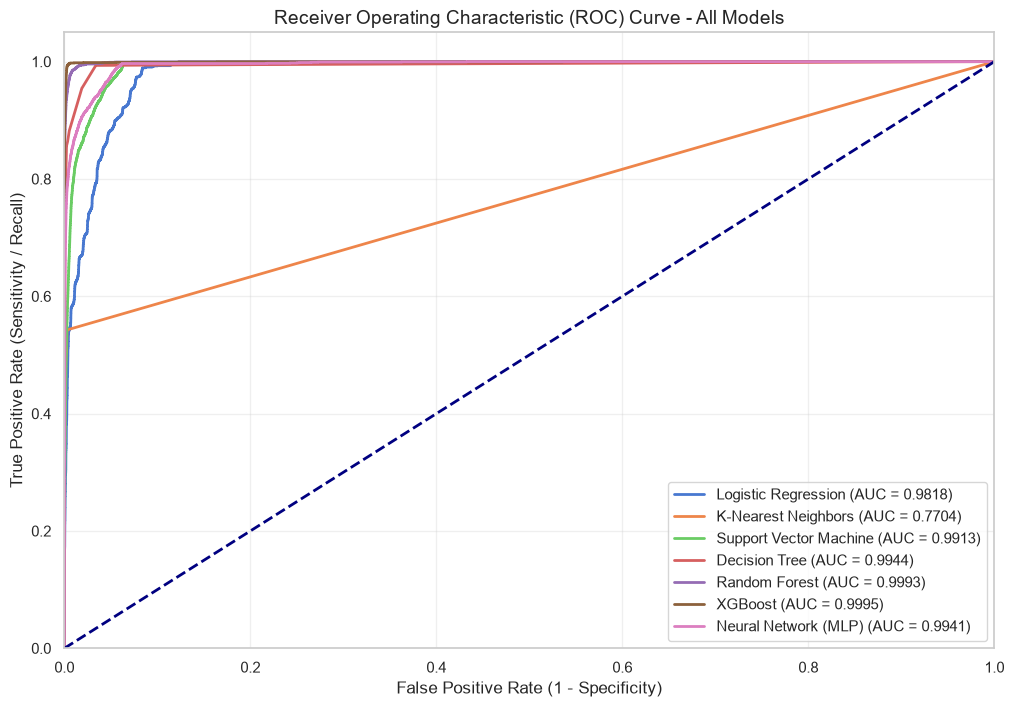

In [67]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(12, 8))

# Loop through models to plot their individual ROC vectors
for name, clf in model_list.items():
    # 1. Handle LinearSVM (uses decision_function)
    if name == "Support Vector Machine":
        y_scores = clf.decision_function(x_test)
        
    # 2. FIX THE ERROR: Handle Keras Neural Network (uses predict directly)
    elif name == "Neural Network (MLP)":
        # Flatten ensures the array is 1D matching y_test
        y_scores = clf.predict(x_test, batch_size=2048).flatten() 
        
    # 3. Handle standard Scikit-Learn / XGBoost models (use predict_proba)
    else:
        y_scores = clf.predict_proba(x_test)[:, 1]
        
    # Compute False Positive Rate, True Positive Rate, and AUC
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)
    
    # Plot line on the chart
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.4f})')

# Plot the baseline diagonal (random guessing line)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

# Chart Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve - All Models')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

# Save the plot directly to your system
plt.savefig("all_models_roc_auc.png", dpi=300, bbox_inches="tight")
plt.show()


933/933 ━━━━━━━━━━━━━━━━━━━━ 1s 634us/step


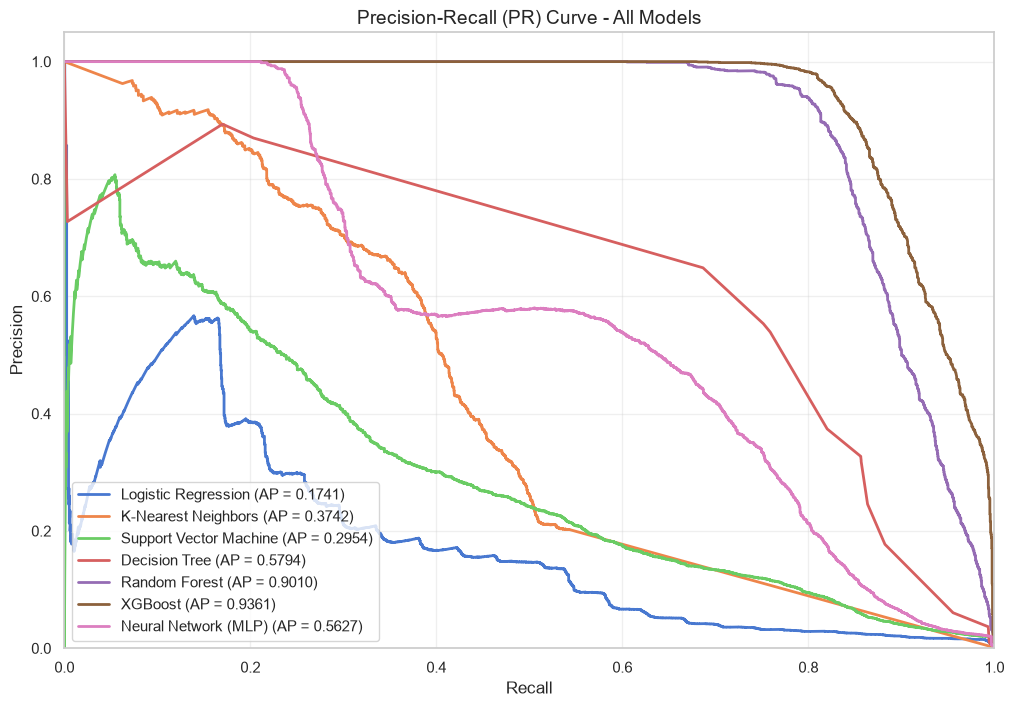

In [69]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(12, 8))

for name, clf in model_list.items():
    # 1. Handle LinearSVM (uses decision_function)
    if name == "Support Vector Machine":
        y_scores = clf.decision_function(x_test)
        
    # 2. FIX THE ERROR: Handle Keras Neural Network (uses predict directly)
    elif name == "Neural Network (MLP)":
        # Flatten drops the 2D output shape to a 1D vector matching y_test
        y_scores = clf.predict(x_test, batch_size=2048).flatten()
        
    # 3. Handle standard Scikit-Learn / XGBoost models (use predict_proba)
    else:
        y_scores = clf.predict_proba(x_test)[:, 1]
        
    # Calculate Precision, Recall vectors and Average Precision (AP) score
    precision, recall, _ = precision_recall_curve(y_test, y_scores)
    ap_score = average_precision_score(y_test, y_scores)
    
    # Plot line on the chart
    plt.plot(recall, precision, lw=2, label=f'{name} (AP = {ap_score:.4f})')

# Chart Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall (PR) Curve - All Models')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

# Save the plot directly to your system
plt.savefig("all_models_pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()


#### Summary:

###### XGBoost is the top-performing model, achieving the highest Average Precision (AP = 0.9361), closely followed by Random Forest (AP = 0.9010). Both ensemble tree-based models significantly outperform the linear, instance-based, and neural network alternatives on this highly imbalanced dataset.

#### Performance Breakdown by Architecture Group

###### • Ensemble Tree Models (Best): XGBoost and Random Forest maintain near-perfect precision (~1.0) even as recall scales out to approximately 0.8, showing exceptional stability and minimal false alarms.
###### • Mid-Tier Classifiers: Decision Tree (AP = 0.5794) and the Neural Network (AP = 0.5627) offer moderate stability but experience sharp precision drops much earlier in the recall curve (around 0.2 to 0.4 recall).
###### • Baseline Classifiers (Worst): K-Nearest Neighbors (AP = 0.3742), Support Vector Machine (AP = 0.2954), and Logistic Regression (AP = 0.1741) struggle significantly, with precision degrading rapidly even at low recall thresholds.


### Feature Importance in XGBoost

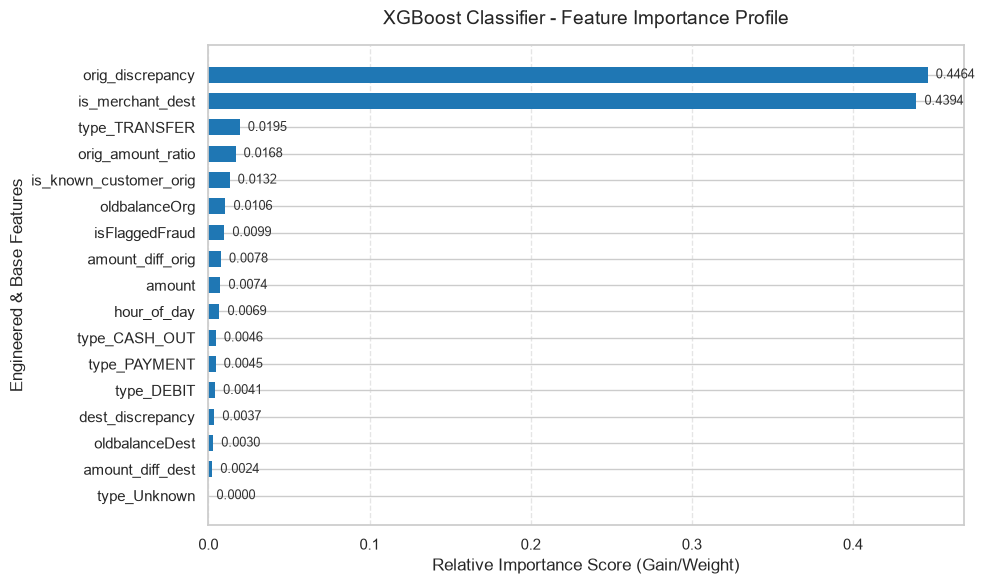

=== Sorted Feature Importance Values ===
               Feature  Importance
      orig_discrepancy    0.446356
      is_merchant_dest    0.439368
         type_TRANSFER    0.019468
     orig_amount_ratio    0.016848
is_known_customer_orig    0.013176
         oldbalanceOrg    0.010576
        isFlaggedFraud    0.009881
      amount_diff_orig    0.007765
                amount    0.007426
           hour_of_day    0.006852
         type_CASH_OUT    0.004607
          type_PAYMENT    0.004514
            type_DEBIT    0.004136
      dest_discrepancy    0.003654
        oldbalanceDest    0.002967
      amount_diff_dest    0.002407
          type_Unknown    0.000000


In [70]:
# 1. Map feature names to their respective importance values
importance_scores = xgb_model.feature_importances_

df_importance = pd.DataFrame(
    {"Feature": features, "Importance": importance_scores}
).sort_values(by="Importance", ascending=True)  # Ascending order for horizontal chart

# 2. Initialize the plot layout
plt.figure(figsize=(10, 6))

# 3. Create the horizontal bar plot
# We use a solid corporate color block with thin grid lines for a professional aesthetic
bars = plt.barh(
    df_importance["Feature"],
    df_importance["Importance"],
    color="#1f77b4",
    edgecolor="none",
    height=0.6,
)

# 4. Add data labels to the end of each bar for precise scannability
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.005,  # Slight offset to keep the text outside the bar
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        va="center",
        ha="left",
        fontsize=9,
        color="#333333",
    )

# 5. Chart Styling & Formatting
plt.xlabel("Relative Importance Score (Gain/Weight)")
plt.ylabel("Engineered & Base Features")
plt.title("XGBoost Classifier - Feature Importance Profile", pad=15)
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Tight boundaries prevent label truncation on export
plt.tight_layout()

# 6. Save the visualization directly to your local computer
plt.savefig("xgboost_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Print the sorted text output for explicit verification
print("=== Sorted Feature Importance Values ===")
print(df_importance.sort_values(by="Importance", ascending=False).to_string(index=False))
